# **Section 3: Advanced data exploration and feature selection**

In this notebook, we will perform feature selection to reduce the number of features in our data set. We will decide which features to keep based on the **training data** only to prevent data leakage. The selected features are then applied to test data. We will select features according to the following strategies: 

- **Remove features with little variace**. First of all, we will remove features with very little variance as they do not provide information useful for a machine learning classification problem. We already saw in notebook 1 that our dataset contains a significant amount of features that are either only 0 or only 1 for most samples. We will remove these features here.
- **Selecting features associated with resistance (using SelectKBest)**. We will use SelectKBest from scikit learn to keep only the most discriminative features. We will use a Chi2 score and keep all features significantly associated to resistance profile.

#### **Contents:**
1. **Load the data**


2. **Remove near-constant features**
   - 2.1. Visualizing variance for all features
   - 2.2 Removing low variance features
   - 2.3. 

3. **Select top features using SelectKBest**


4. **Save selected feature matrix**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, chi2
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
import warnings
warnings.filterwarnings('ignore')

# Set styles
sns.set_style('whitegrid')
sns.set_palette('pastel')

## **1. Load Data**

In [3]:
# Load training features and labels
snp_train = pd.read_csv('Data/snp_train.csv', index_col=0)
snp_test = pd.read_csv("Data/snp_test.csv", index_col=0)
sxt_train = pd.read_csv('Data/SXT_train.csv', index_col=0)
sxt_test = pd.read_csv("Data/SXT_test.csv", index_col=0)

print(f'Training set shape: {snp_train.shape}')
print(f'Labels shape: {sxt_train.shape}')
print(f'Resistance distribution:')
print(sxt_train.value_counts())

Training set shape: (176, 78850)
Labels shape: (176, 1)
Resistance distribution:
SXT_binary
1             103
0              73
Name: count, dtype: int64


## **2. Remove near-constant features**
Let's now remove features that have very little variance (that are almost the same for all samples). Let's choose which features to remove on the training set and then remove the same features from the test set.

Binary features follow a Bernouilli distribution, with variance var = p(1-p) with p the fraction of samples equal to 1. So for instance, the variance will be equivalent to 0.16 if 80% of the features are equal to 1 (var = 0.8*0.2 = 0.16). For perfectly balanced features, the variance is equal to 0.25. We will calculate the variance for all features and remove features with little variance.

### **2.1 Visualizing the variance for all features**
Let's first visualize the variance for all of our features using a histogram.

In [7]:
p = snp_train.mean(axis=0)
variance = p * (1 - p) 

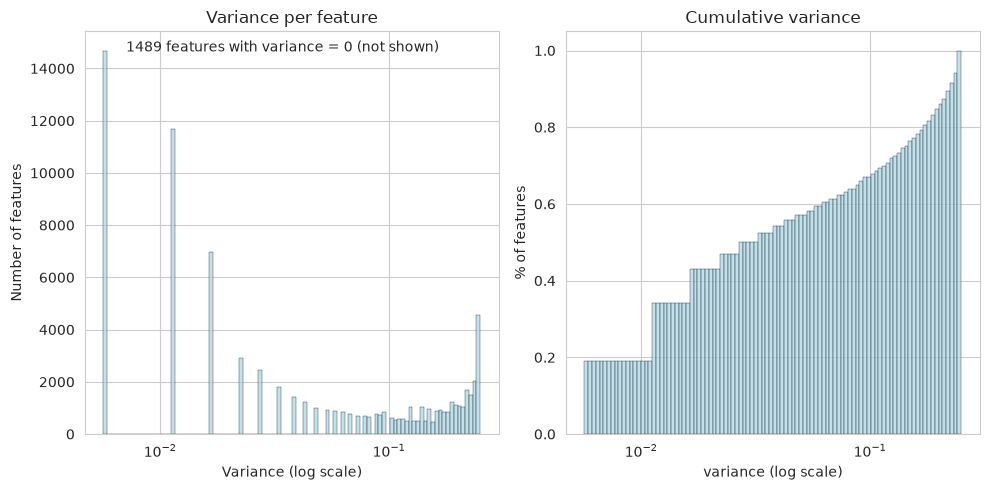

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

n_zeros = (variance == 0).sum()
var_nonzero = variance[variance > 0]

sns.histplot(var_nonzero, bins=100, log_scale=True, color='lightblue', edgecolor='black', ax=axes[0])
axes[0].set_title("Variance per feature")
axes[0].set_xlabel("Variance (log scale)")
axes[0].set_ylabel("Number of features")
axes[0].set_xscale("log")
axes[0].text(0.1, 0.95, f"{n_zeros} features with variance = 0 (not shown)", transform=axes[0].transAxes)

sns.histplot(var_nonzero, bins=100, log_scale=True, color='lightblue', edgecolor='black', ax=axes[1], cumulative=True, stat="density")
axes[1].set_title("Cumulative variance")
axes[1].set_xlabel("variance (log scale)")
axes[1].set_ylabel("% of features")
axes[1].set_xscale("log")

plt.tight_layout()
plt.savefig('Figures/03_Std.png', dpi=300, bbox_inches='tight')
plt.show()

We see that there are a lot of features with very little variance (1489 features have 0 variance). We see also that around 20% of our features have less than 0.01 variance. Looking at these graphs, I have decided to remove all features that have a variance smaller than 0.015. 

### **2.2 Removing low variance features**

In [9]:
low_variance_mask = variance < 0.015
print(f'{low_variance_mask.sum()} features have low variance')

27846 features have low variance


In [10]:
print(f'Before removing features: {snp_train.shape}')
snp_train = snp_train.loc[:,~low_variance_mask]

print(f'After removing features: {snp_train.shape}')

Before removing features: (176, 78850)
After removing features: (176, 51004)


In [11]:
print(f'Before removing features: {snp_test.shape}')
snp_test = snp_test.loc[:, ~low_variance_mask]
print(f'After removing features: {snp_test.shape}')

Before removing features: (50, 78850)
After removing features: (50, 51004)


## **3. Select Features using SelectKBest**

I will now select features using SelectKBest and an Chi2 score. This identifies the most discriminative features. I will choose to keep only features that are significantly associated with the resistance profile of our samples.

### **3.1 Score all features**

In [12]:
from scipy.stats import false_discovery_control

# Calculate Chi2 for all features
selector = SelectKBest(score_func=chi2, k='all')
selector.fit(snp_train, sxt_train.iloc[:, 0])

feature_importance = pd.DataFrame({
    'feature': snp_train.columns,
    'chi2': selector.scores_,
    'p_value': selector.pvalues_,
})

feature_importance['p_adj'] = false_discovery_control(feature_importance['p_value'], method='bh')
feature_importance = feature_importance.sort_values('chi2', ascending=False)

significant = feature_importance['p_adj'] < 0.05
print(f"Significant features: {significant.sum()} ({significant.mean() * 100:.1f}%)")

Significant features: 1199 (2.4%)


### **3.2 Select significant features (p < 0.05)**
There are actually very little features that are significantly associated with the resistance profile. Let's select only these for modeling. 

In [13]:
# Select all significant features
sig_features = feature_importance.loc[feature_importance['p_adj'] < 0.05, 'feature']
snp_train_selected = snp_train[sig_features]
snp_test_selected = snp_test[sig_features]

print(f'Features before selection: {snp_train.shape[1]}')
print(f'Features after selection: {snp_train_selected.shape[1]}')

Features before selection: 51004
Features after selection: 1199


### **3.3 SNPs per feature (training set)**
Let's visualize the total number and percentage of SNPs in the remaining features for the training set.

In [14]:
counts_regions = snp_train_selected.sum(axis=0)
percentage_regions = snp_train_selected.mean(axis=0) * 100

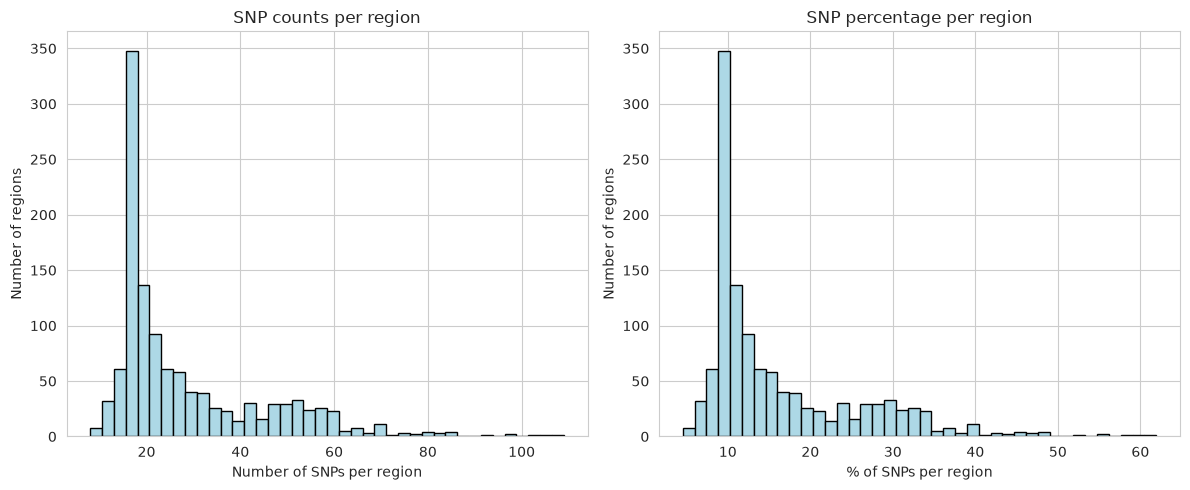

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of SNPs per region')
axes[0].set_ylabel('Number of regions')
axes[0].set_title('SNP counts per region')

axes[1].hist(percentage_regions, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of SNPs per region')
axes[1].set_ylabel('Number of regions')
axes[1].set_title('SNP percentage per region')

plt.tight_layout()
plt.savefig('Figures/03_SNPs_per_feature_train.png', dpi=300, bbox_inches='tight')
plt.show()

We see that this distribution looks much better suited for a machine learning model than what we had before feature selection (in notebook 1). Indeed, there are now no features with either 0 or 100% of values equal to 1. Let's also quickly see what happens in the test set.

### **3.4 SNPs per feature (test set)**

In [16]:
counts_regions_test = snp_test_selected.sum(axis=0)
percentage_regions_test = snp_test_selected.mean(axis=0) * 100

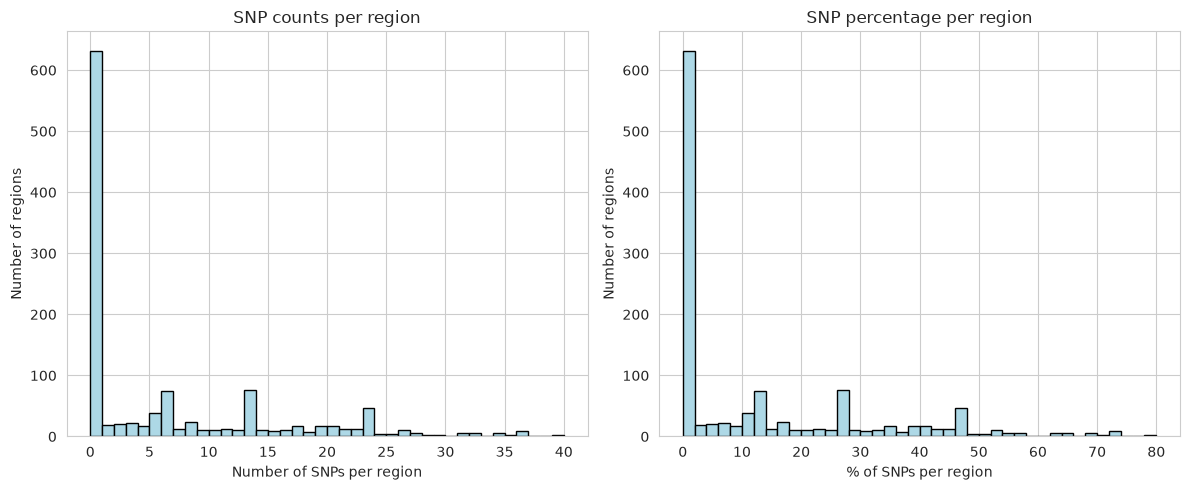

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions_test, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of SNPs per region')
axes[0].set_ylabel('Number of regions')
axes[0].set_title('SNP counts per region')

axes[1].hist(percentage_regions_test, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of SNPs per region')
axes[1].set_ylabel('Number of regions')
axes[1].set_title('SNP percentage per region')

plt.tight_layout()
plt.savefig('Figures/03_SNPs_per_feature_test.png', dpi=300, bbox_inches='tight')
plt.show()

In the test set, there are still quite some features that contain 0 SNPs. these features weren't removed, as they contain SNPs in the training set. It will be interesting if models will perform well on this test set even though it seems to be quite different from the training set!

## **4. Removing duplicated features**
Finally, we will remove identical features by keeping only one of them. We will however save which original features were removed for downstream biomarker analysis.

### **4.1 Identifying duplicates**
let's first identify duplicated samples and keep only the first one. 

In [18]:
# Find identical columns and create a single cluster per unique presence/absence pattern
_, first_idx, labels = np.unique(
    snp_train_selected.to_numpy(), axis=1, return_index=True, return_inverse=True
)
labels = labels.ravel()                 # cluster number for every SNP
new_features = snp_train_selected.columns[first_idx]

print(f"We go from {snp_train_selected.shape[1]} features to {len(new_features)} features")

We go from 1199 features to 796 features


### **4.2 Create new clusters**
Let's now create the clusters and save the information about which SNP feature went into each newly created cluster.

In [31]:
# Saving which SNP went into which cluster
clusters = pd.DataFrame({
    "cluster": labels,
    "snp": snp_train_selected.columns,
})

clusters["cluster_size"] = clusters["cluster"].map(clusters["cluster"].value_counts())
clusters = clusters.sort_values(["cluster", "snp"])
clusters.to_csv("Data/clusters.csv", index=False)

Finally, let's reduce the size of the feature matrix to contain only the newly created clusters

In [22]:
col_names = range(len(new_features))
snp_train_reduced = snp_train_selected[new_features]
snp_train_reduced.columns = col_names

snp_test_reduced = snp_test_selected[new_features]
snp_test_reduced.columns = col_names

### **4.3 SNPs per feature (training set)**
Let's visualize the total number and percentage of SNPs in the remaining features for the training set.

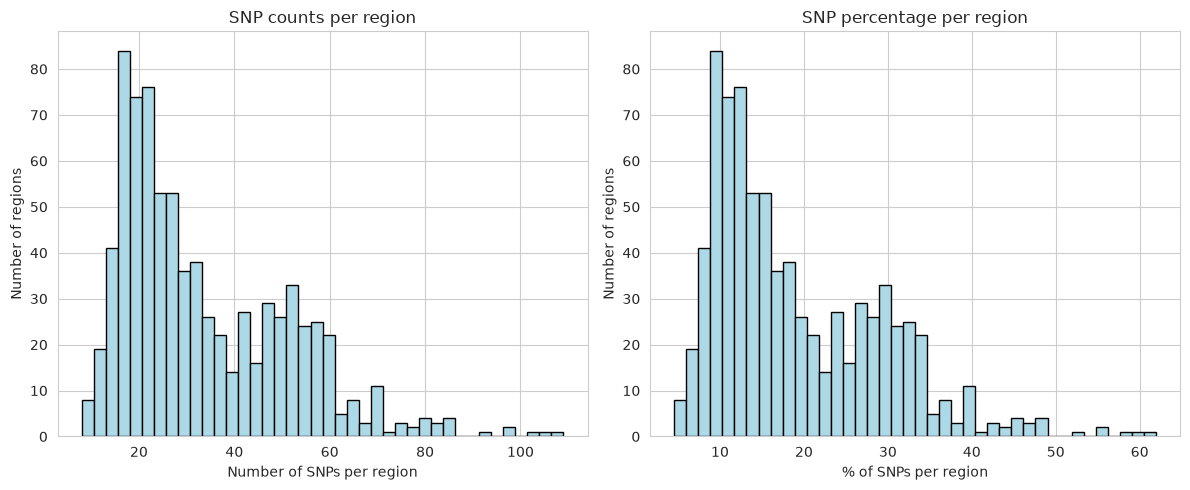

In [23]:
counts_regions = snp_train_reduced.sum(axis=0)
percentage_regions = snp_train_reduced.mean(axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of SNPs per region')
axes[0].set_ylabel('Number of regions')
axes[0].set_title('SNP counts per region')

axes[1].hist(percentage_regions, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of SNPs per region')
axes[1].set_ylabel('Number of regions')
axes[1].set_title('SNP percentage per region')

plt.tight_layout()
plt.savefig('Figures/03_SNPs_per_feature_train_reduced.png', dpi=300, bbox_inches='tight')
plt.show()

In comparison to before, we see that the big peak around 18 SNPs per region (10% SNPs per region) disappeared, suggesting that this peak mainly came from features that were identical to each other. It's good that we removed these features, as they did not contain additional information for modeling. 

### **4.4 SNPs per feature (test set)**
Let's visualize the total number and percentage of SNPs in the remaining features for the test set.

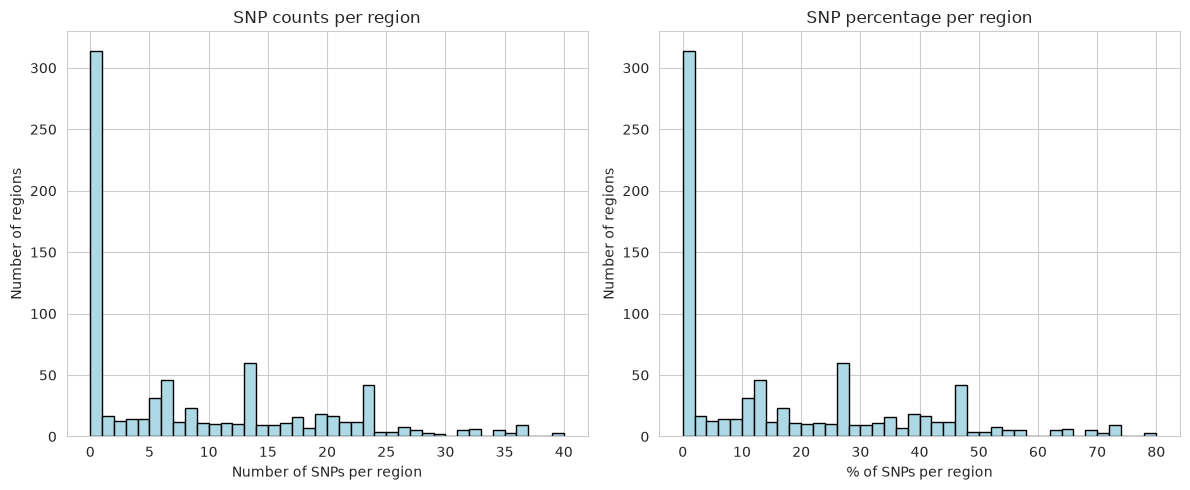

In [24]:
counts_regions = snp_test_reduced.sum(axis=0)
percentage_regions = snp_test_reduced.mean(axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of SNPs per region')
axes[0].set_ylabel('Number of regions')
axes[0].set_title('SNP counts per region')

axes[1].hist(percentage_regions, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of SNPs per region')
axes[1].set_ylabel('Number of regions')
axes[1].set_title('SNP percentage per region')

plt.tight_layout()
plt.savefig('Figures/03_SNPs_per_feature_train_reduced.png', dpi=300, bbox_inches='tight')
plt.show()

The number of regions that had 0 SNPs went down significantly in comparison to before (from around 600 to around 300 features). Most of these regions were apparently duplicated!

### **4.5 Dendogram**
Finally, let's repeat the analysis we did in the first notebook to see how our strains cluster together taking these new features into acount, and how this relates to their resistance profile. 

In [25]:
X = snp_train_reduced.values
dist = X @ (1 - X).T + (1 - X) @ X.T
dist_df = pd.DataFrame(dist, index=snp_train_reduced.index, columns=snp_train_reduced.index)

In [26]:
Z = linkage(squareform(dist_df.values, checks=False), method="average")

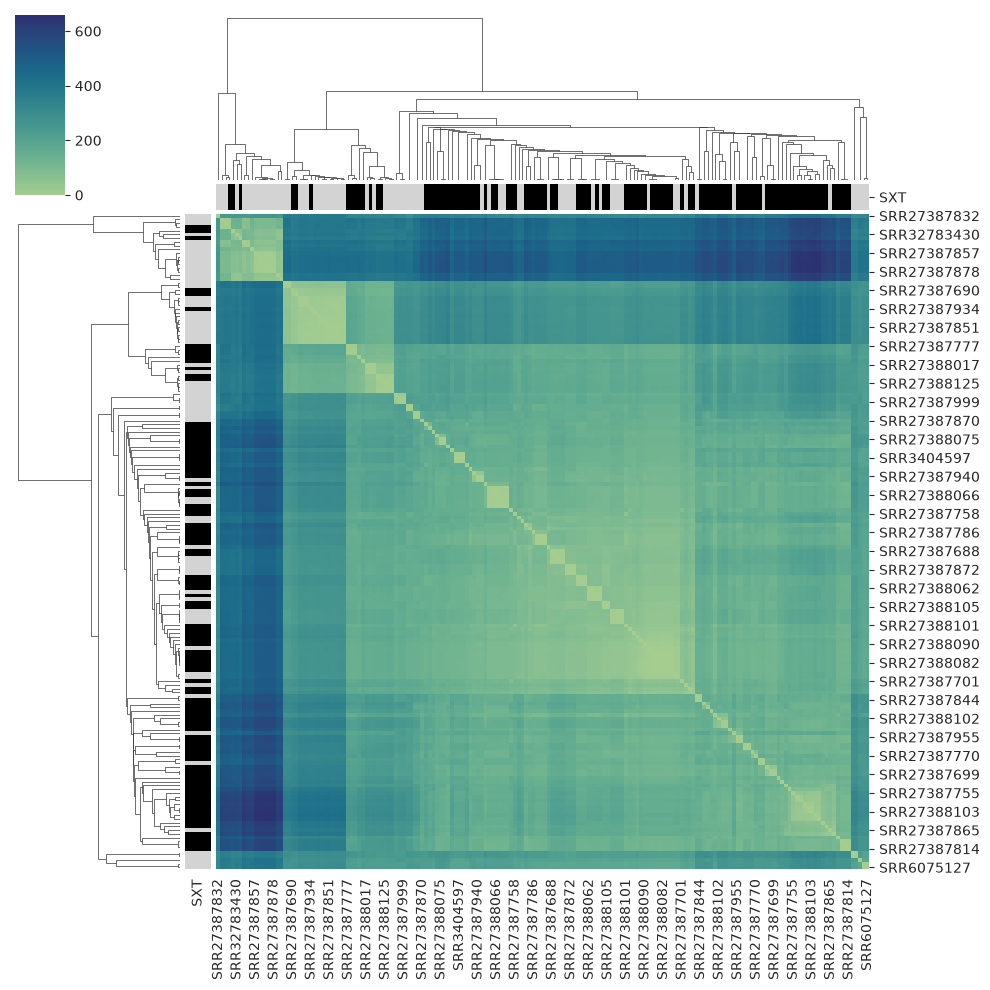

In [27]:
palette = {0: "lightgrey", 1: "black"}
strain_colors = sxt_train.iloc[:, 0].map(palette).rename("SXT")

sns.clustermap(dist_df, cmap="crest", row_linkage=Z, col_linkage=Z, row_colors=strain_colors, col_colors=strain_colors)

plt.savefig('Figures/03_Clustering.png', dpi=600, bbox_inches='tight')
plt.show()

This is an interesting graph. In comparison to the graph in notebook 1, strains with similar antibiotic profiles now seem to cluster much more together. The selected features look promising for a machine learning approach. 

## **4. Save Selected Features**

In [28]:
# Save selected training features
snp_train_reduced.to_csv('Data/snp_train_selected.csv')
sxt_train.to_csv("Data/SXT_train_selected.csv")

# Save selected test features
snp_test_reduced.to_csv('Data/snp_test_selected.csv')
sxt_test.to_csv("Data/SXT_test_selected.csv")

In [29]:
print(f'Final training data shape: {snp_train_reduced.shape}')
print(f'Final test data shape: {snp_test_reduced.shape}')

print(f'Final training label shape: {sxt_train.shape}')
print(f'Final test label shape: {sxt_test.shape}')

Final training data shape: (176, 796)
Final test data shape: (50, 796)
Final training label shape: (176, 1)
Final test label shape: (50, 1)
